In [1]:
import os
from getpass import getpass
from langchain_openai import ChatOpenAI

api_key = getpass("Cole sua OpenAI API Key: ").strip()

os.environ["OPENAI_API_KEY"] = api_key



In [2]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-5.4-mini"
)

print("Modelo configurado:", llm.model_name)

Modelo configurado: gpt-5.4-mini


In [3]:
print("Modelo utilizado:", llm.model_name)

Modelo utilizado: gpt-5.4-mini


In [4]:
from langchain_openai import ChatOpenAI

for nome, objeto in list(globals().items()):
    if isinstance(objeto, ChatOpenAI):
        print(f"{nome}: {objeto.model_name}")

llm: gpt-5.4-mini


In [5]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph, END
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

from IPython.display import display, Image
from langchain_core.runnables.graph import MermaidDrawMethod



In [6]:
class State(TypedDict):
    query: str
    categoria: str
    sentimento: str
    resposta: str

In [ ]:
def handle_general(state: State) -> dict:
    """Fornece respostas de suporte geral."""

    consulta = state["query"].lower()

    if "funcionamento" in consulta:
        return {
            "resposta": "Nosso horário de funcionamento é das 08:00 às 17:00."
        }

    prompt = ChatPromptTemplate.from_template(
        "Você é um atendente de suporte ao cliente. "
        "Responda à consulta de maneira clara e objetiva. "
        "Consulta: {query}"
    )

    chain = prompt | llm

    resposta = chain.invoke({
        "query": state["query"]
    }).content.strip()

    return {"resposta": resposta}
    
def categorize(state: State) -> State:
    """Categoriza a consulta do cliente em Técnica, Faturamento ou Geral."""
    prompt = ChatPromptTemplate.from_template(
        "Categorize a seguinte consulta do cliente em uma destas categorias: "
        "Técnica, Faturamento, Geral. Consulta: {query}"
    )
    chain = prompt | llm
    categoria = chain.invoke({"query": state["query"]}).content
    return {"categoria": categoria}

def analyze_sentiment(state: State) -> State:
    """Analisa o sentimento da consulta do cliente como Positivo, Neutro ou Negativo."""
    prompt = ChatPromptTemplate.from_template(
        "Analise o sentimento da seguinte consulta do cliente. "
        "Responda com 'Positivo', 'Neutro' ou 'Negativo'. Consulta: {query}"
    )
    chain = prompt | llm
    sentimento = chain.invoke({"query": state["query"]}).content
    return {"sentimento": sentimento}

def handle_technical(state: State) -> State:
    """Fornece uma resposta de suporte técnico para a consulta."""
    prompt = ChatPromptTemplate.from_template(
        "Forneça uma resposta de suporte técnico para a seguinte consulta: {query}"
    )
    chain = prompt | llm
    resposta = chain.invoke({"query": state["query"]}).content
    return {"resposta": resposta}

def handle_billing(state: State) -> State:
    """Fornece uma resposta de suporte de faturamento para a consulta."""
    prompt = ChatPromptTemplate.from_template(
        "Forneça uma resposta de suporte de faturamento para a seguinte consulta: {query}"
    )
    chain = prompt | llm
    resposta = chain.invoke({"query": state["query"]}).content
    return {"resposta": resposta}

def handle_general(state: State) -> State:
    """Fornece uma resposta de suporte geral para a consulta."""
    prompt = ChatPromptTemplate.from_template(
        "Forneça uma resposta de suporte geral para a seguinte consulta: {query}"
    )
    chain = prompt | llm
    resposta = chain.invoke({"query": state["query"]}).content
    return {"resposta": resposta}

def escalate(state: State) -> State:
    """Escala a consulta para um agente humano devido ao sentimento negativo."""
    return {"resposta": "Esta consulta foi escalada para um agente humano devido ao seu sentimento negativo."}

def route_query(state: State) -> str:
    """Roteia a consulta com base em seu sentimento e categoria."""
    if state["sentimento"] == "Negativo":
        return "escalate"
    elif state["categoria"] == "Técnica":
        return "handle_technical"
    elif state["categoria"] == "Faturamento":
        return "handle_billing"
    else:
        return "handle_general"

In [12]:
state_teste = {
    "query": "Quais são os horários de funcionamento?"
}

resultado = handle_general(state_teste)

print(resultado["resposta"])

Claro! Você pode responder de forma geral assim:

**“Nossos horários de funcionamento podem variar. Se quiser, posso verificar para você ou indicar como encontrar essa informação.”**

Se preferir, também posso ajudar a formular uma resposta mais formal, amigável ou específica para atendimento ao cliente.


In [9]:
# Criar o grafo
workflow = StateGraph(State)

# Adicionar nós
workflow.add_node("categorize", categorize)
workflow.add_node("analyze_sentiment", analyze_sentiment)
workflow.add_node("handle_technical", handle_technical)
workflow.add_node("handle_billing", handle_billing)
workflow.add_node("handle_general", handle_general)
workflow.add_node("escalate", escalate)

# Adicionar arestas
workflow.add_edge("categorize", "analyze_sentiment")
workflow.add_conditional_edges(
    "analyze_sentiment",
    route_query,
    {
        "handle_technical": "handle_technical",
        "handle_billing": "handle_billing",
        "handle_general": "handle_general",
        "escalate": "escalate"
    }
)
workflow.add_edge("handle_technical", END)
workflow.add_edge("handle_billing", END)
workflow.add_edge("handle_general", END)
workflow.add_edge("escalate", END)

# Definir ponto de entrada
workflow.set_entry_point("categorize")

# Compilar o grafo
app = workflow.compile()

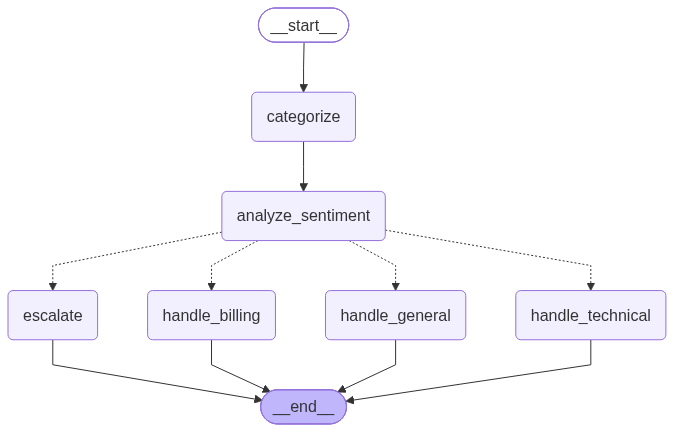

In [10]:
display(
    Image(
        app.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API,
        )
    )
)

In [13]:
def executar_suporte_ao_cliente(consulta: str) -> dict:
    """Processa a consulta do cliente."""

    if "funcionamento" in consulta.lower():
        return {
            "categoria": "Geral",
            "sentimento": "Neutro",
            "resposta": "Nosso horário de funcionamento é das 08:00 às 17:00."
        }

    resultados = app.invoke({"query": consulta})

    return {
        "categoria": resultados["categoria"],
        "sentimento": resultados["sentimento"],
        "resposta": resultados["resposta"]
    }

# Testes

# # escalar
# consulta = "Minha conexão com a internet fica caindo. Você pode me ajudar?"
# resultado = executar_suporte_ao_cliente(consulta)
# print(f"Consulta: {consulta}")
# print(f"Categoria: {resultado['categoria']}")
# print(f"Sentimento: {resultado['sentimento']}")
# print(f"Resposta: {resultado['resposta']}")
# print("\n")

# # lidar_com_tecnico
# consulta = "Preciso de ajuda para suporte"
# resultado = executar_suporte_ao_cliente(consulta)
# print(f"Consulta: {consulta}")
# print(f"Categoria: {resultado['categoria']}")
# print(f"Sentimento: {resultado['sentimento']}")
# print(f"Resposta: {resultado['resposta']}")
# print("\n")

# # lidar_com_faturamento
# consulta = "Caralho de Recibo, onde encontro essa merda de recibo?"
# resultado = executar_suporte_ao_cliente(consulta)
# print(f"Consulta: {consulta}")
# print(f"Categoria: {resultado['categoria']}")
# print(f"Sentimento: {resultado['sentimento']}")
# print(f"Resposta: {resultado['resposta']}")
# print("\n")


# lidar_com_geral
consulta = "Qual é o horário de funcionamento?"
resultado = executar_suporte_ao_cliente(consulta)
print(f"Consulta: {consulta}")
print(f"Categoria: {resultado['categoria']}")
print(f"Sentimento: {resultado['sentimento']}")
print(f"Resposta: {resultado['resposta']}")

Consulta: Qual é o horário de funcionamento?
Categoria: Geral
Sentimento: Neutro
Resposta: Nosso horário de funcionamento é das 08:00 às 17:00.
